In [3]:
#Pandas and Numpy are two of the most popular libraries in Python for data manipulation and analysis. Pandas provides data structures like DataFrames and Series, which are essential for handling structured data, while Numpy offers support for large, multi-dimensional arrays and matrices, along with a collection of mathematical functions to operate on these arrays.
import pandas as pd
import numpy as np

#importing the necessary libraries for data manipulation and analysis.
#importing a csv file containing data into a Pandas DataFrame.
Online_Retail_data = pd.read_csv('online_retail_II.csv', encoding='ISO-8859-1')

## Step 1 : Cleaning the dataset

In [4]:
#Viewing the first few rows of the DataFrame to get an overview of the data.
Online_Retail_data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [5]:
#General information about the DataFrame, including the number of non-null entries, data types of each column, and memory usage.
Online_Retail_data.info()

#getting a statistical summary of the numerical columns in the DataFrame, including count, mean, standard deviation, minimum, maximum, and quartile values.
Online_Retail_data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


,Quantity,Price,Customer ID
count,541910.000000,541910.000000,406830.000000
mean,9.552234,4.611138,15287.684160
std,218.080957,96.759765,1713.603074
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [6]:
#Data Cleaning and Preprocessing
#First, we will check for any missing values in the DataFrame and handle them appropriately. We will also remove any duplicate entries to ensure the data is clean and ready for analysis.
#Checking for missing values in the DataFrame.
Online_Retail_data.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [7]:
#Completing the missing values in the 'Description' column by comparing the 'Description' values with the 'StockCode' values. If a match is found, we will fill in the missing 'Description' value with the corresponding 'Description' from the matched 'StockCode'.
#Filling missing values in the 'Description' column based on 'StockCode'. The one without a matched description will be filled with 'No Description'.
#Viewing unique values in the 'Description' column to understand the variety of product descriptions available in the dataset and to identify any potential issues with missing or inconsistent descriptions.
Online_Retail_data['Description'] = Online_Retail_data.groupby('StockCode')['Description'].transform(lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else x.fillna('No Description'))
Online_Retail_data['Description'].unique()

<StringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',            'JAM MAKING SET WITH JARS',
 ...
                              'lost??',                                 '???',
           'LETTER "U" BLING KEY RING',                                 'wet',
                           'wet boxes',                     '????damages????',
                            'mixed up',                                'lost',
  'CREAM HANGING HEART T-LIGHT HOLDER',         'PAPER CRAFT , LITTLE BIRDIE']
Length: 4224, dtype: str

In [10]:
#Removing * in some description values to ensure consistency in the product descriptions and to avoid any potential issues during analysis.
Online_Retail_data['Description'] = Online_Retail_data['Description'].str.replace('*', '', regex=False)
#Replace "?", "??" and "???" in the 'Description' column with the matched value with StockCode to handle any remaining missing or unclear descriptions and to maintain consistency in the dataset.
Online_Retail_data['Description'] = Online_Retail_data.groupby('StockCode')['Description'].transform(lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else x.fillna('No Description'))
Online_Retail_data['Description'].unique()
#Removing last description values that are still unclear or missing after the previous steps to ensure that the dataset is clean and ready for analysis.
Online_Retail_data = Online_Retail_data[Online_Retail_data['Description'] != 'No Description']
#Removing observations in description values where the description is not uppercase to ensure consistency in the product descriptions and to avoid any potential issues during analysis.
Online_Retail_data = Online_Retail_data[Online_Retail_data['Description'].str.isupper()]
#Viewing description values in the 'Description' column to ensure that the data cleaning and preprocessing steps have been successful and that the dataset is now clean and ready for analysis.
Online_Retail_data['Description'].unique()

<StringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',            'JAM MAKING SET WITH JARS',
 ...
             'SNACK TRAY PAISLEY PARK',      'SET OF 6 RIBBONS COUNTRY STYLE',
        'SNACK TRAY RED VINTAGE DOILY', 'SET OF 6 RIBBONS PERFECTLY PRETTY  ',
              'SET OF 6 RIBBONS PARTY',      'SET 10 CARDS SNOWY ROBIN 17099',
 'SET 10 CARDS SWIRLY XMAS TREE 17104',           'LETTER "U" BLING KEY RING',
  'CREAM HANGING HEART T-LIGHT HOLDER',         'PAPER CRAFT , LITTLE BIRDIE']
Length: 4018, dtype: str

In [14]:
#Dividing the dataset into two seperate datasets one without missing values in "Customer ID" and one with missing values in "Customer ID" to handle the missing values appropriately and to ensure that the analysis is based on complete and accurate data.
#In the second dataset with missing values in "Customer ID", we will fill in the missing values with a placeholder value of 0 to indicate that the customer ID is unknown or missing.
Online_Retail_data_with_missing_customer_id = Online_Retail_data[Online_Retail_data['Customer ID'].isnull()]
Online_Retail_data_without_missing_customer_id = Online_Retail_data[Online_Retail_data['Customer ID'].notnull()]
{Online_Retail_data_with_missing_customer_id.shape[0], Online_Retail_data_without_missing_customer_id.shape[0]}
#Replace missing values in the 'Customer ID' column with 0 to indicate that the customer ID is unknown or missing.
Online_Retail_data_with_missing_customer_id['Customer ID'] = Online_Retail_data_with_missing_customer_id['Customer ID'].fillna(0)
#Viewing the first few rows of the DataFrame with missing values in "Customer ID" to ensure that the missing values have been appropriately handled and filled with the placeholder value of 0.
Online_Retail_data_with_missing_customer_id.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
622,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,12/1/10 11:52,0.00,0.0,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/10 14:32,2.51,0.0,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/10 14:32,2.51,0.0,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/10 14:32,0.85,0.0,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/10 14:32,1.66,0.0,United Kingdom


In [16]:
#Viewing the first few rows of the DataFrame with missing values in "Customer ID" to ensure that the missing values have been appropriately handled and filled with the placeholder value of 0.
Online_Retail_data_with_missing_customer_id.head()
Online_Retail_data_without_missing_customer_id.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [20]:
#Make a summary of the number by invoice number to see how many items are in each invoice and to identify any potential issues with the data, such as invoices with an unusually high or low number of items.
Online_Retail_data_without_missing_customer_id.groupby('Invoice')['Quantity'].sum().reset_index().sort_values(by='Quantity', ascending=False).head(10)
#Add a new column 'TotalPrice' and "Total Quantity" by invoice number to calculate the total price and total quantity of items in each invoice, which will be useful for further analysis and insights into customer purchasing behavior.
Online_Retail_data_without_missing_customer_id['TotalPrice'] = Online_Retail_data_without_missing_customer_id['Quantity'] * Online_Retail_data_without_missing_customer_id['Price']
Online_Retail_data_without_missing_customer_id.groupby('Invoice')['TotalPrice'].sum().reset_index().sort_values(by='TotalPrice', ascending=False).head(10)

,Invoice,TotalPrice
18401,581483,168469.60
1905,541431,77183.60
7885,556444,38970.00
12359,567423,31698.16
8071,556917,22775.93
14384,572209,22206.00
12351,567381,22104.80
10789,563614,21880.44
5435,550461,21535.90
14296,572035,20277.92


In [23]:
#Verifying that the 'TotalPrice' column has been correctly calculated by checking the first few rows of the DataFrame to ensure that the total price for each invoice is accurate and consistent with the quantity and price of the items purchased.
Online_Retail_data_without_missing_customer_id.head()
#Verify if StockCode respect the format and is unique for each Description to ensure that the product descriptions are consistent and accurate, and to avoid any potential issues during analysis.
Online_Retail_data_without_missing_customer_id.groupby('StockCode')['Description'].nunique().reset_index().query('Description > 1')

,StockCode,Description
41,16156L,2
98,17107D,3
115,20622,2
167,20725,2
259,20914,2
...,...,...
3292,85184C,2
3293,85185B,2
3356,90014A,2
3357,90014B,2


In [27]:
#Verify the format of the StockCode column to ensure it follows the expected pattern and is consistent across all rows.
Online_Retail_data_without_missing_customer_id['StockCode'].str.match(r'^[A-Z0-9]{5}$').sum()
#Removing any rows with StockCode that do not match the expected format to ensure consistency and accuracy in the dataset.
Online_Retail_data_without_missing_customer_id = Online_Retail_data_without_missing_customer_id[Online_Retail_data_without_missing_customer_id['StockCode'].str.match(r'^[A-Z0-9]{5}$')]
#Match the StockCode with the Description to ensure that each StockCode corresponds to a unique Description and to avoid any potential issues during analysis.
Online_Retail_data_without_missing_customer_id.groupby('StockCode')['Description'].nunique().reset_index().query('Description > 1')
#Take one description for each StockCode to ensure that the dataset is clean and ready for analysis.
Online_Retail_data_without_missing_customer_id = Online_Retail_data_without_missing_customer_id.groupby('StockCode').first().reset_index()


In [28]:
#Verifying that each StockCode corresponds to a unique Description by checking the number of unique descriptions for each StockCode to ensure that the dataset is clean and ready for analysis.
Online_Retail_data_without_missing_customer_id.groupby('StockCode')['Description'].nunique().reset_index().query('Description > 1')

,StockCode,Description


In [29]:
#Verifying that the quantity values are all positive by checking for any negative values in the 'Quantity' column to ensure that the dataset is clean and ready for analysis.
Online_Retail_data_without_missing_customer_id[Online_Retail_data_without_missing_customer_id['Quantity'] < 0]
Online_Retail_data_without_missing_customer_id = Online_Retail_data_without_missing_customer_id[Online_Retail_data_without_missing_customer_id['Quantity'] > 0]

In [36]:
#Transforming the 'InvoiceDate' column to a datetime format to facilitate time-based analysis and to ensure that the data is in a consistent and usable format.
Online_Retail_data_without_missing_customer_id['InvoiceDate'] = pd.to_datetime(Online_Retail_data_without_missing_customer_id['InvoiceDate'], format='%d-%m-%Y %H:%M')

In [38]:
#Verifying the data types of each column in the DataFrame to ensure that they are appropriate for analysis and to identify any potential issues with data types that may need to be addressed.
Online_Retail_data_without_missing_customer_id.dtypes

StockCode                 str
Invoice                   str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
TotalPrice            float64
dtype: object

In [39]:
#Keep invoices with a positive price to ensure that the dataset is clean and ready for analysis.
Online_Retail_data_without_missing_customer_id = Online_Retail_data_without_missing_customer_id[Online_Retail_data_without_missing_customer_id['Price'] > 0]    

In [41]:
#Find outliers in the 'Price' column by calculating the z-score for each value and identifying any values that are more than 3 standard deviations away from the mean, which may indicate potential outliers or anomalies in the data.
from scipy import stats
z_scores = stats.zscore(Online_Retail_data_without_missing_customer_id['Price'])
outliers = Online_Retail_data_without_missing_customer_id[abs(z_scores) > 3]
print(f"Number of outliers in 'Price' column: {outliers.shape[0]}")

Number of outliers in 'Price' column: 16


In [ ]:
#Since the number of outliers in the 'Price' column is relatively small, we will keep them in the dataset for further analysis, as they may represent valid transactions or unique cases that could provide valuable insights into customer purchasing behavior.

In [42]:
#Viewing country values in the 'Country' column to understand the distribution of customers across different countries and to identify any potential issues with missing or inconsistent country values.
Online_Retail_data_without_missing_customer_id['Country'].unique()

<StringArray>
[         'France',  'United Kingdom',         'Belgium',            'EIRE',
          'Cyprus',       'Lithuania',        'Portugal',         'Germany',
         'Iceland',           'Italy',          'Norway',       'Australia',
 'Channel Islands',           'Japan',           'Spain',     'Switzerland',
          'Poland',     'Netherlands',       'Singapore',         'Denmark',
     'Unspecified',         'Finland']
Length: 22, dtype: str

In [43]:
#Viewing the cleaned and preprocessed DataFrame to ensure that the data is ready for analysis and to identify any potential issues that may need to be addressed before proceeding with further analysis.
Online_Retail_data_without_missing_customer_id.head()

,StockCode,Invoice,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,10002,536370,INFLATABLE POLITICAL GLOBE,48,2010-12-01 08:45:00,0.85,12583.0,France,40.80
1,10080,545060,GROOVY CACTUS INFLATABLE,2,2011-02-27 13:47:00,0.85,15547.0,United Kingdom,1.70
2,10120,536863,DOGGY RUBBER,1,2010-12-03 11:19:00,0.21,17967.0,United Kingdom,0.21
3,10125,536464,MINI FUNKY DESIGN TAPES,2,2010-12-01 12:23:00,0.85,17968.0,United Kingdom,1.70
4,10133,536446,COLOURING PENCILS BROWN TUBE,5,2010-12-01 12:15:00,0.85,15983.0,United Kingdom,4.25


In [45]:
#Viewing the shape of the cleaned and preprocessed DataFrame to understand the size of the dataset and to identify any potential issues with the number of rows and columns that may need to be addressed before proceeding with further analysis.
Online_Retail_data_without_missing_customer_id.shape
Online_Retail_data_without_missing_customer_id.info()

<class 'pandas.DataFrame'>
Index: 2732 entries, 0 to 2787
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   StockCode    2732 non-null   str           
 1   Invoice      2732 non-null   str           
 2   Description  2732 non-null   str           
 3   Quantity     2732 non-null   int64         
 4   InvoiceDate  2732 non-null   datetime64[us]
 5   Price        2732 non-null   float64       
 6   Customer ID  2732 non-null   float64       
 7   Country      2732 non-null   str           
 8   TotalPrice   2732 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 213.4 KB


## Step 2 : Exploratory Data Analysis

In [46]:
#Descriptive statistics of the cleaned and preprocessed DataFrame to understand the distribution of numerical values in the dataset and to identify any potential issues with outliers or skewed distributions that may need to be addressed before proceeding with further analysis.
Online_Retail_data_without_missing_customer_id.describe()

,Quantity,InvoiceDate,Price,Customer ID,TotalPrice
count,2732.000000,2732,2732.000000,2732.000000,2732.000000
mean,70.911054,2011-01-31 13:15:57.430453,3.623807,15488.672767,113.156391
min,1.000000,2010-12-01 08:26:00,0.070000,12346.000000,0.140000
25%,1.000000,2010-12-01 14:40:15,1.250000,14159.000000,3.900000
50%,4.000000,2010-12-05 15:47:00,1.950000,15525.000000,10.300000
75%,12.000000,2011-03-02 12:12:00,3.750000,17095.250000,18.000000
max,80995.000000,2011-12-09 09:15:00,295.000000,18257.000000,168469.600000
std,2101.903955,NaN,9.582589,1739.344568,3544.964686


In [47]:
#Descriptive statistics of price and total price to understand the distribution of these key metrics in the dataset and to identify any potential issues with outliers or skewed distributions that may need to be addressed before proceeding with further analysis.
Online_Retail_data_without_missing_customer_id[['Price', 'TotalPrice']].describe()

,Price,TotalPrice
count,2732.000000,2732.000000
mean,3.623807,113.156391
std,9.582589,3544.964686
min,0.070000,0.140000
25%,1.250000,3.900000
50%,1.950000,10.300000
75%,3.750000,18.000000
max,295.000000,168469.600000


In [49]:
#Importing the necessary libraries for data visualization, including Matplotlib and Seaborn, which will be used to create various plots and charts to visualize the data and gain insights into customer purchasing behavior.
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [50]:
#Graph global style settings for Matplotlib and Seaborn to ensure that the visualizations are consistent and visually appealing, and to facilitate effective communication of insights derived from the data.
plt.style.use('seaborn-v0_8')
sns.set_style('whitegrid')

In [51]:
#Aggregating the total revenue (sum of TotalPrice) and total quantity (sum of Quantity) by month to understand the overall sales performance and customer purchasing behavior over time, and to identify any potential trends or patterns that may be useful for further analysis.
monthly_sales = Online_Retail_data_without_missing_customer_id.groupby(Online_Retail_data_without_missing_customer_id['InvoiceDate'].dt.month).agg({'TotalPrice': 'sum', 'Quantity': 'sum'})
monthly_sales

,TotalPrice,Quantity
InvoiceDate,,
1,79880.19,75523
2,732.80,844
3,3189.50,1066
4,1515.82,720
5,3433.65,2525
6,2168.68,1252
7,1358.59,1303
8,1184.64,1227
9,1367.06,843


In [52]:
#Replace numerical month values with their corresponding month names to facilitate better understanding and interpretation of the monthly sales data, and to enhance the clarity of visualizations and reports generated from this data.
monthly_sales.index = monthly_sales.index.map({1: 'January', 2: 'February', 3: 'March', 4: 'April', 5: 'May', 6: 'June', 7: 'July', 8: 'August', 9: 'September', 10: 'October', 11: 'November', 12: 'December'})

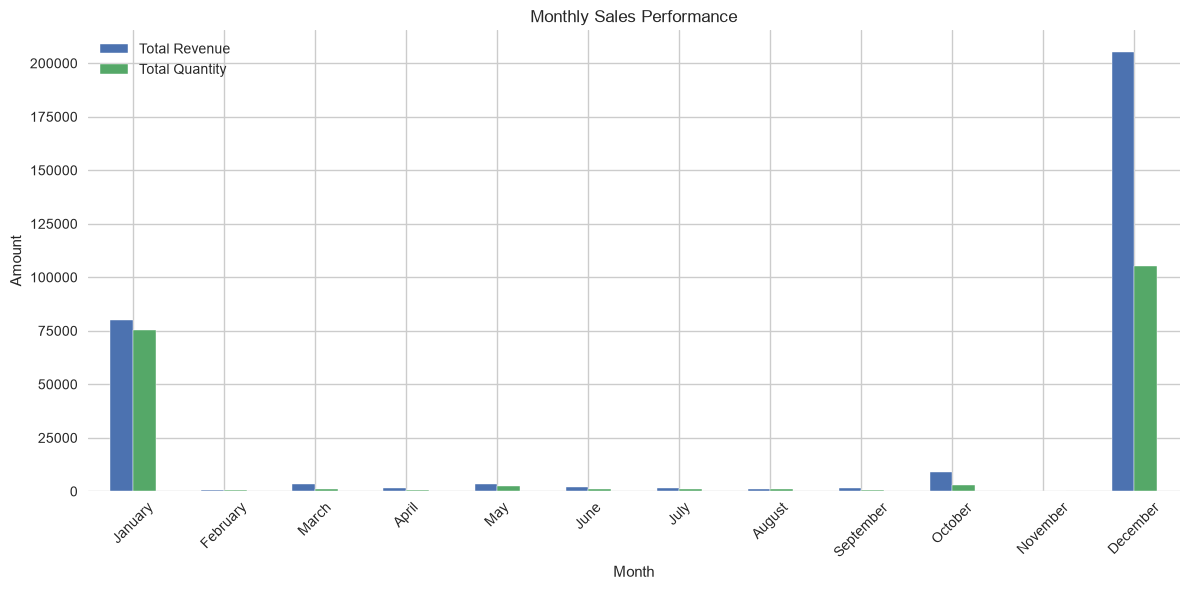

In [53]:
#Making a bar plot to visualize the total revenue and total quantity by month to gain insights into customer purchasing behavior and to identify any potential trends or patterns that may be useful for further analysis.
plt.figure(figsize=(12, 6))
monthly_sales.plot(kind='bar', y=['TotalPrice', 'Quantity'], ax=plt.gca())
plt.title('Monthly Sales Performance')
plt.xlabel('Month')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.legend(['Total Revenue', 'Total Quantity'])
plt.tight_layout()
plt.show()

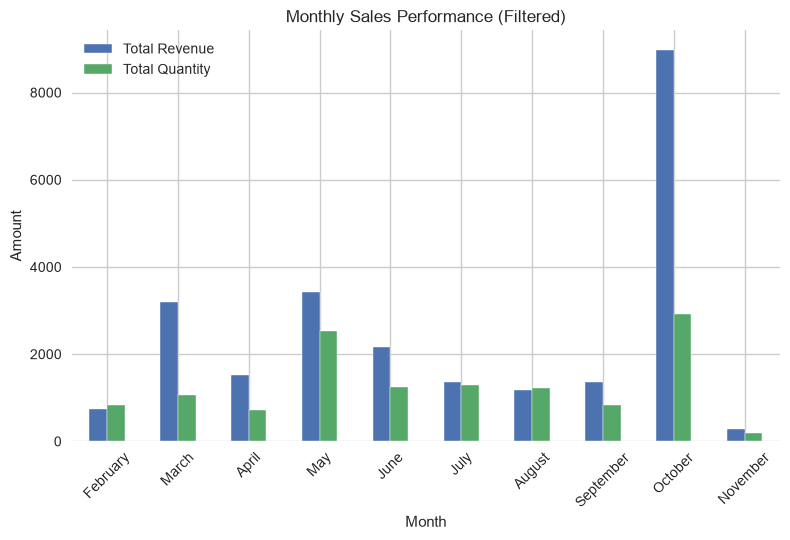

In [54]:
#Remaking the bar plot without the months of january and december to focus on the core months of the year and to identify any potential trends or patterns that may be more relevant for further analysis.
monthly_sales_filtered = monthly_sales.loc[['February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November']]
monthly_sales_filtered.plot(kind='bar', y=['TotalPrice', 'Quantity'], ax=plt.gca())
plt.title('Monthly Sales Performance (Filtered)')
plt.xlabel('Month')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.legend(['Total Revenue', 'Total Quantity'])
plt.tight_layout()
plt.show()

In [ ]:
#Commenting on the importance of analyzing customer purchasing behavior and identifying potential trends or patterns in the data to inform business decisions and strategies.


In [56]:
#Finding the top 10 customers by total revenue to identify the most valuable customers and to inform targeted marketing and sales strategies that can help to increase customer loyalty and retention.
top_customers = Online_Retail_data_without_missing_customer_id.groupby('Customer ID')['TotalPrice'].sum().reset_index().sort_values(by='TotalPrice', ascending=False).head(10)
top_customers

,Customer ID,TotalPrice
534,16446.0,168469.60
0,12346.0,77183.60
783,18102.0,6214.74
481,16029.0,3012.12
505,16210.0,2036.32
208,14156.0,1799.55
380,15299.0,1531.05
677,17511.0,1239.12
674,17450.0,1097.82
789,18133.0,931.50


In [58]:
#Finding the top 10 products by total revenue and total quantity to identify the most popular products and to inform inventory management and product development strategies that can help to increase sales and customer satisfaction.
top_products = Online_Retail_data_without_missing_customer_id.groupby('StockCode')[['TotalPrice', 'Quantity']].sum().reset_index().sort_values(by='TotalPrice', ascending=False).head(10)   
top_products
#Adding a description column to the top_products DataFrame to provide additional context and information about the products, which can help to inform inventory management and product development strategies that can help to increase sales and customer satisfaction.
top_products = top_products.merge(Online_Retail_data_without_missing_customer_id[['StockCode', 'Description']].drop_duplicates(), on='StockCode', how='left')
top_products

,StockCode,TotalPrice,Quantity,Description
0,23843,168469.60,80995,"PAPER CRAFT , LITTLE BIRDIE"
1,23166,77183.60,74215,MEDIUM CERAMIC TOP STORAGE JAR
2,21137,1627.20,480,BLACK RECORD COVER FRAME
3,21897,1097.82,342,POTTING SHED CANDLE CITRONELLA
4,84950,1003.20,1824,ASSORTED COLOUR T-LIGHT HOLDER
5,23167,931.50,1350,SMALL CERAMIC TOP STORAGE JAR
6,23531,801.36,168,WALL ART BIG LOVE
7,23538,773.28,216,WALL ART VINTAGE HEART
8,23540,750.00,120,WALL ART THE MAGIC FOREST
9,79321,733.44,192,CHILLI LIGHTS


In [59]:
#Showing the top 10 products by total revenue and total quantity to identify the most popular products and to inform inventory management and product development strategies that can help to increase sales and customer satisfaction.
top_products

,StockCode,TotalPrice,Quantity,Description
0,23843,168469.60,80995,"PAPER CRAFT , LITTLE BIRDIE"
1,23166,77183.60,74215,MEDIUM CERAMIC TOP STORAGE JAR
2,21137,1627.20,480,BLACK RECORD COVER FRAME
3,21897,1097.82,342,POTTING SHED CANDLE CITRONELLA
4,84950,1003.20,1824,ASSORTED COLOUR T-LIGHT HOLDER
5,23167,931.50,1350,SMALL CERAMIC TOP STORAGE JAR
6,23531,801.36,168,WALL ART BIG LOVE
7,23538,773.28,216,WALL ART VINTAGE HEART
8,23540,750.00,120,WALL ART THE MAGIC FOREST
9,79321,733.44,192,CHILLI LIGHTS


In [ ]:
#Analysing the distribution of invoice values to understand the distribution of invoices across different customers and to identify any potential issues with missing or inconsistent invoice values that may need to be addressed before proceeding with further analysis.
invoice_distribution = Online_Retail_data_without_missing_customer_id.groupby('Customer ID')['TotalPrice'].sum().reset_index()
invoice_distribution


,Customer ID,TotalPrice
0,12346.0,77183.60
1,12347.0,17.40
2,12357.0,25.20
3,12370.0,83.50
4,12377.0,10.08
...,...,...
800,18229.0,15.00
801,18239.0,26.70
802,18245.0,10.20
803,18252.0,39.90


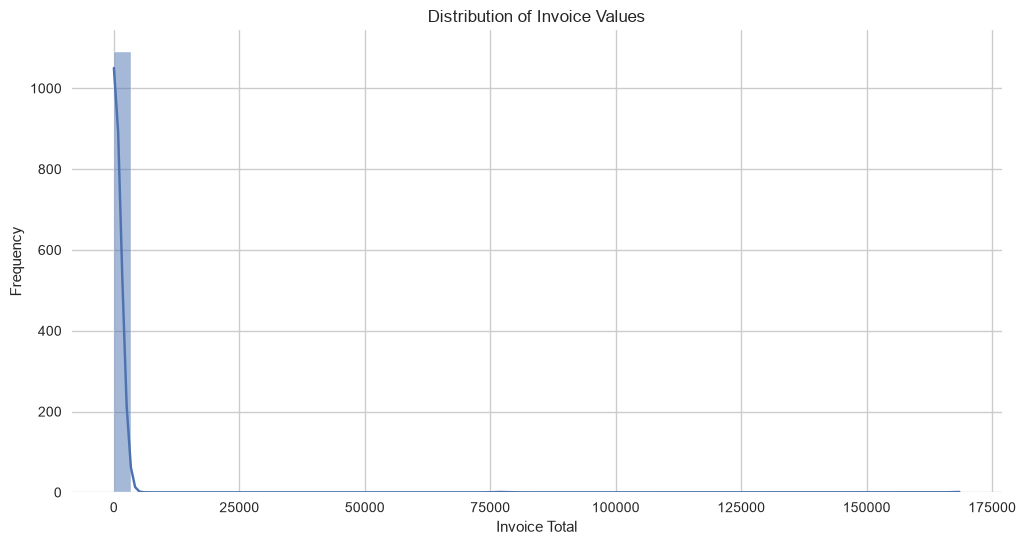

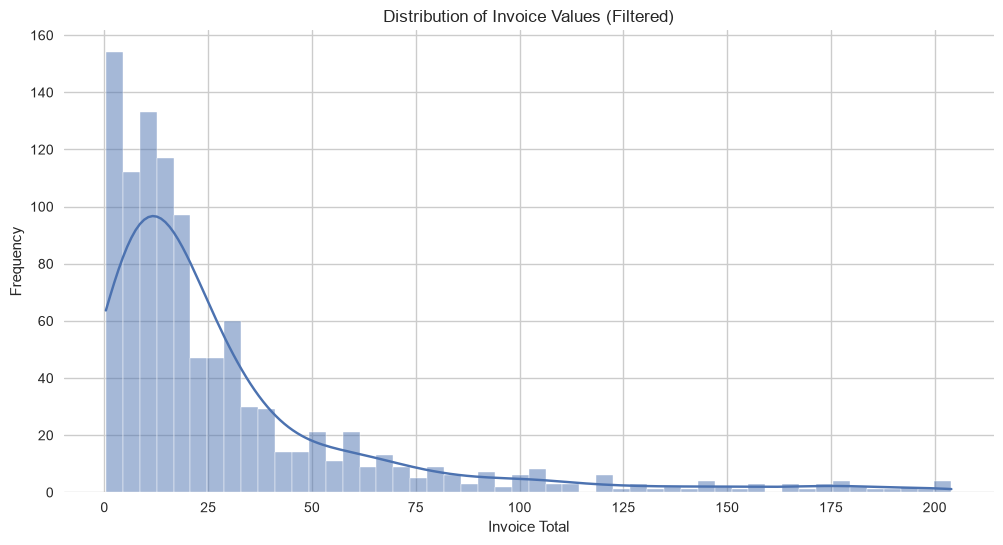

In [67]:
#Making a histogram to visualize the distribution of invoice values to gain insights into customer purchasing behavior and to identify any potential trends or patterns that may be useful for further analysis.
invoice_totals = Online_Retail_data_without_missing_customer_id.groupby('Invoice')['TotalPrice'].sum()
plt.figure(figsize=(12, 6))
sns.histplot(invoice_totals.values, bins=50, kde=True)
plt.title('Distribution of Invoice Values')
plt.xlabel('Invoice Total')
plt.ylabel('Frequency')
plt.show()
#Remaking the histogram without the outliers to focus on the core distribution of invoice values and to identify any potential trends or patterns that may be more relevant for further analysis.
invoice_totals_filtered = invoice_totals[invoice_totals < invoice_totals.quantile(0.95)]
plt.figure(figsize=(12, 6))
sns.histplot(invoice_totals_filtered.values, bins=50, kde=True)
plt.title('Distribution of Invoice Values (Filtered)')
plt.xlabel('Invoice Total')
plt.ylabel('Frequency')
plt.show()


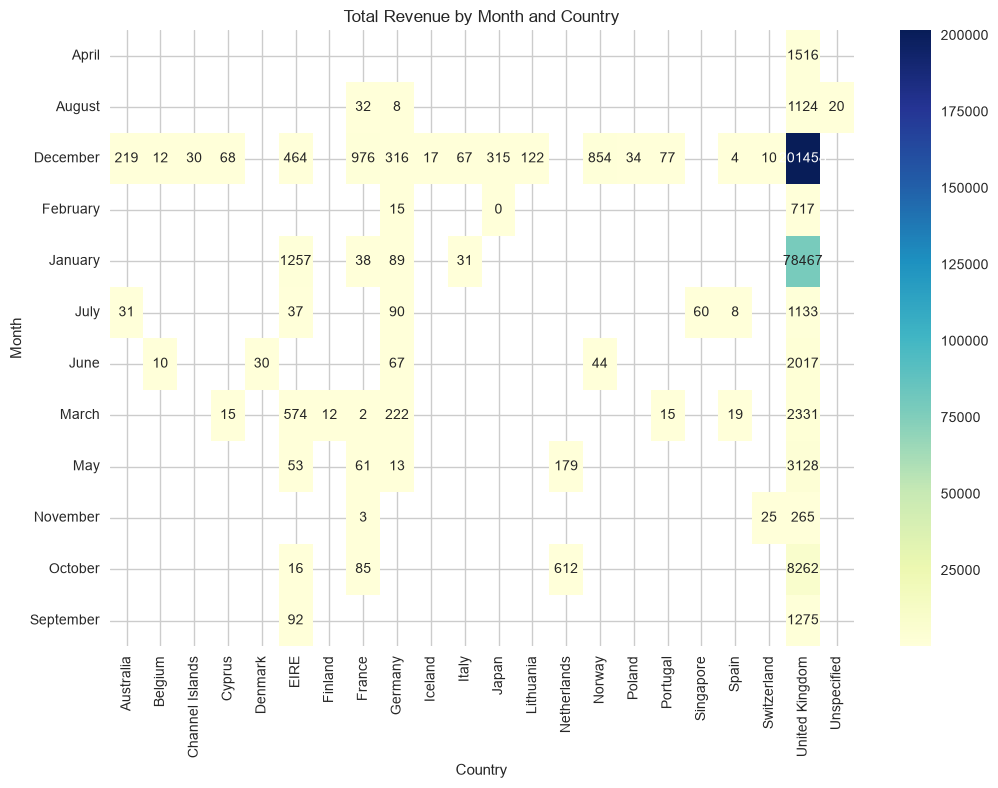

In [69]:
#Making before a columns of month and year from the 'InvoiceDate' column to facilitate time-based analysis and to enable the creation of pivot tables and visualizations that can provide insights into customer purchasing behavior over time.
Online_Retail_data_without_missing_customer_id['Month'] = Online_Retail_data_without_missing_customer_id['InvoiceDate'].dt.month_name()
#Making a heatmap with a pivot table of total revenue by month and country to visualize the relationship between these two variables and to identify any potential trends or patterns that may be useful for further analysis.
pivot_table = Online_Retail_data_without_missing_customer_id.pivot_table(index=Online_Retail_data_without_missing_customer_id['Month'], columns=Online_Retail_data_without_missing_customer_id['Country'], values='TotalPrice', aggfunc='sum')
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Total Revenue by Month and Country')
plt.xlabel('Country')
plt.ylabel('Month')
plt.show()

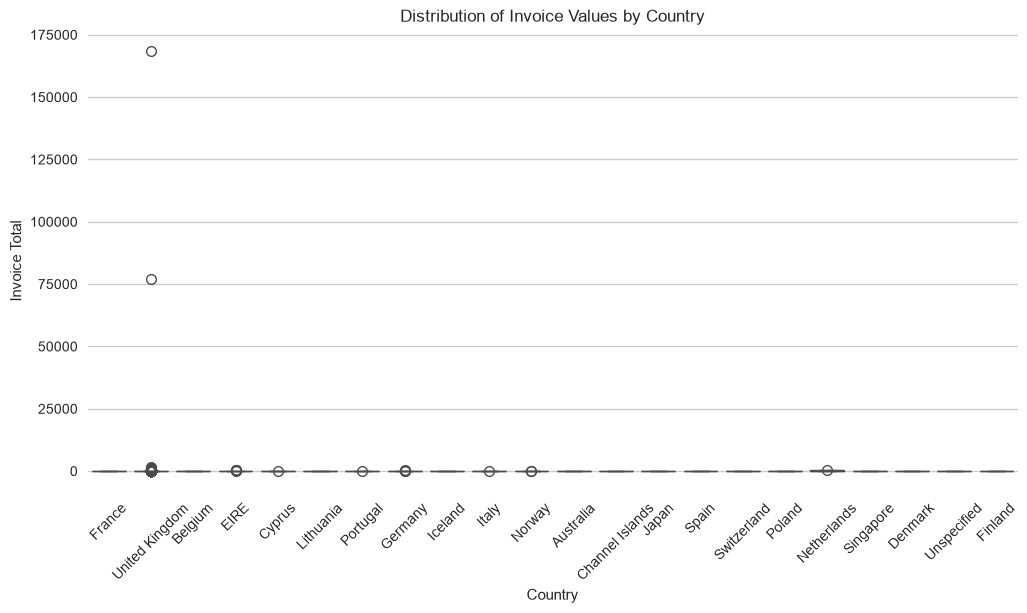

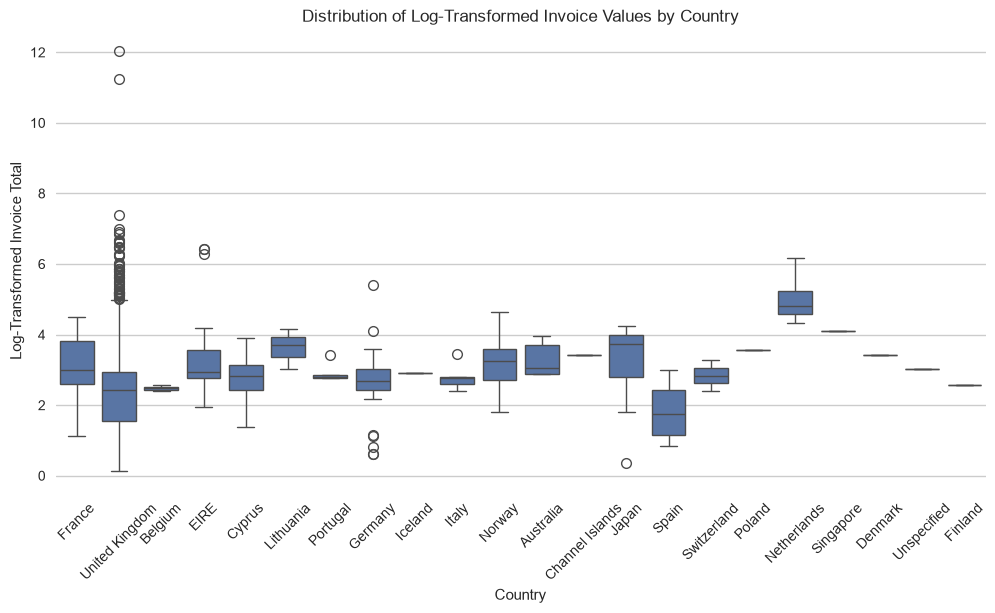

In [71]:
#Making a boxplot to visualize the distribution of invoice values by country to gain insights into customer purchasing behavior across different countries and to identify any potential trends or patterns that may be useful for further analysis.
plt.figure(figsize=(12, 6))
sns.boxplot(x='Country', y='TotalPrice', data=Online_Retail_data_without_missing_customer_id)
plt.title('Distribution of Invoice Values by Country')
plt.xlabel('Country')
plt.ylabel('Invoice Total')
plt.xticks(rotation=45)
plt.show()
#Taking a logarithmic transformation of the 'TotalPrice' column to reduce the impact of extreme values and to facilitate better visualization and analysis of the distribution of invoice values by country.
Online_Retail_data_without_missing_customer_id['LogTotalPrice'] = np.log1p(Online_Retail_data_without_missing_customer_id['TotalPrice'])
#Remaking the boxplot with the logarithmic transformation of the 'TotalPrice' column to reduce the impact of extreme values and to facilitate better visualization and analysis of the distribution of invoice values by country.
plt.figure(figsize=(12, 6))
sns.boxplot(x='Country', y='LogTotalPrice', data=Online_Retail_data_without_missing_customer_id)
plt.title('Distribution of Log-Transformed Invoice Values by Country')
plt.xlabel('Country')
plt.ylabel('Log-Transformed Invoice Total')
plt.xticks(rotation=45)
plt.show()

## Step 3 : Statistical test and analysis

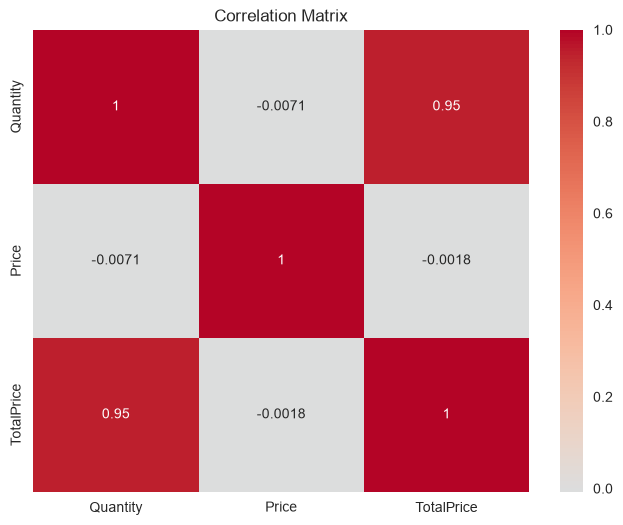

In [72]:
#Correlation analysis to understand the relationships between different numerical variables in the dataset and to identify any potential trends or patterns that may be useful for further analysis.
correlation_matrix = Online_Retail_data_without_missing_customer_id[['Quantity', 'Price', 'TotalPrice']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()


In [74]:
#Pearson correlation coefficient to quantify the strength and direction of the linear relationship between different numerical variables in the dataset and to identify any potential trends or patterns that may be useful for further analysis.
corr_val,p_val=stats.pearsonr(Online_Retail_data_without_missing_customer_id['Quantity'], Online_Retail_data_without_missing_customer_id['Price'])
print(f"Correlation coefficient: {corr_val}")
print(f"P-value: {p_val}")
if p_val < 0.05:
    print("The correlation is statistically significant.")
else:
    print("The correlation is not statistically significant.")

Correlation coefficient: -0.00714261235074676
P-value: 0.7090235531577552
The correlation is not statistically significant.


In [76]:
#Importing the necessary libraries for statistical analysis, including the stats module from the SciPy library, which will be used to perform various statistical tests and calculations to gain insights into customer purchasing behavior and to identify any potential trends or patterns that may be useful for further analysis.
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [77]:
#Economic analysis using a OLS regression model to understand the relationship between different variables in the dataset and to identify any potential trends or patterns that may be useful for further analysis.
#Specifying the OLS regression model with 'TotalPrice' as the dependent variable and 'Quantity' and 'Price' as independent variables to analyze the relationship between these variables and to identify any potential trends or patterns that may be useful for further analysis.
formula = 'TotalPrice ~ Quantity + Price'
model = smf.ols(formula=formula, data=Online_Retail_data_without_missing_customer_id).fit() 

#Viewing the summary of the OLS regression model to understand the relationship between 'TotalPrice', 'Quantity', and 'Price', and to identify any potential trends or patterns that may be useful for further analysis.
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             TotalPrice   R-squared:                       0.905
Model:                            OLS   Adj. R-squared:                  0.905
Method:                 Least Squares   F-statistic:                 1.302e+04
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:43:40   Log-Likelihood:                -22988.
No. Observations:                2732   AIC:                         4.598e+04
Df Residuals:                    2729   BIC:                         4.600e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -7.2789     22.354     -0.326      0.7

## Step 4 : Machine learning prediction

In [79]:
#Importing the necessary libraries for machine learning, including scikit-learn, which will be used to build and evaluate predictive models based on the cleaned and preprocessed dataset.
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [81]:
#Creating a new DataFrame with only the relevant columns for machine learning analysis to focus on the key variables that are most likely to influence customer purchasing behavior and to facilitate the development of predictive models.
#Adding a new hour column from the 'InvoiceDate' column to capture potential time-based patterns in customer purchasing behavior and to enhance the predictive power of the machine learning models.
Online_Retail_data_without_missing_customer_id['Hour'] = Online_Retail_data_without_missing_customer_id['InvoiceDate'].dt.hour
Online_Retail_data_for_ml = Online_Retail_data_without_missing_customer_id[['Quantity', 'Price', 'TotalPrice', 'Hour','Month']].copy()


In [85]:
#Selecting the features and target variable for machine learning analysis to build predictive models that can help to understand customer purchasing behavior and to identify any potential trends or patterns that may be useful for further analysis.
X = Online_Retail_data_for_ml[['Quantity', 'Price', 'Hour',]]
y = Online_Retail_data_for_ml['TotalPrice']

In [86]:
#Dividing the dataset into training and testing sets to evaluate the performance of the machine learning models and to ensure that the models are able to generalize well to new, unseen data.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 2185 samples
Testing set size: 547 samples


In [87]:
#Initializing and training a Random Forest Regressor model to predict 'TotalPrice' based on the selected features, which can help to understand customer purchasing behavior and to identify any potential trends or patterns that may be useful for further analysis.
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [89]:
#Predicting 'TotalPrice' for the test set using the trained Random Forest Regressor model to evaluate its performance and to gain insights into customer purchasing behavior based on the selected features.
y_pred_rf = rf_model.predict(X_test)
y_pred_rf

array([3.750000e+00, 1.500000e+01, 1.324080e+01, 4.197000e-01,
       3.262000e+00, 1.324080e+01, 9.120000e-01, 1.700000e+01,
       1.253400e+01, 1.170000e+01, 1.022350e+01, 1.575435e+02,
       5.900000e+00, 2.562000e+00, 4.033020e+01, 1.500000e+01,
       5.762220e+01, 1.650000e+00, 2.500000e+00, 4.200000e+00,
       1.950000e+00, 1.170000e+01, 1.300000e+00, 1.825080e+01,
       1.500000e+01, 1.980000e+01, 1.660200e+01, 1.050000e+01,
       1.153600e+01, 6.074800e+01, 4.690620e+01, 1.770000e+01,
       1.770000e+01, 1.020000e+01, 4.483200e+01, 3.697450e+01,
       2.496000e+01, 5.098800e+00, 1.700000e+00, 5.100000e+00,
       7.860000e+00, 4.950000e+00, 4.392000e+01, 5.097600e+00,
       2.922960e+01, 1.740000e+01, 1.700000e+01, 4.499100e+01,
       1.500000e+01, 1.050000e+01, 7.896000e+01, 1.500000e+01,
       5.040000e+00, 1.635600e+00, 1.008000e+01, 2.932600e+01,
       1.577600e+01, 1.500000e+01, 6.948000e+00, 5.897600e+00,
       3.884400e+00, 2.946800e+01, 1.020000e+01, 1.9900

In [90]:
#Evaluating the performance of the Random Forest Regressor model using various metrics, including Mean Squared Error (MSE), Root Mean Squared Error (RMSE), R-squared (R2), and Mean Absolute Error (MAE), to assess the accuracy and effectiveness of the model in predicting 'TotalPrice' based on the selected features.
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
print(f"Random Forest Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.2f}")
print(f"R-squared (R2): {r2_rf:.2f}")
print(f"Mean Absolute Error (MAE): {mae_rf:.2f}")

Random Forest Regressor Performance:
Mean Squared Error (MSE): 87.61
Root Mean Squared Error (RMSE): 9.36
R-squared (R2): 0.97
Mean Absolute Error (MAE): 1.57


In [91]:
#Explain the significance of the performance metrics of the Random Forest Regressor model
print("The performance metrics of the Random Forest Regressor model provide insights into how well the model is able to predict 'TotalPrice' based on the selected features. The Mean Squared Error (MSE) and Root Mean Squared Error (RMSE) indicate the average squared difference between the predicted and actual values, with lower values indicating better performance. The R-squared (R2) value represents the proportion of variance in the dependent variable that is predictable from the independent variables, with values closer to 1 indicating a better fit. The Mean Absolute Error (MAE) measures the average absolute difference between predicted and actual values, with lower values indicating better performance. Overall, these metrics help to assess the accuracy and effectiveness of the model in predicting customer purchasing behavior.")

The performance metrics of the Random Forest Regressor model provide insights into how well the model is able to predict 'TotalPrice' based on the selected features. The Mean Squared Error (MSE) and Root Mean Squared Error (RMSE) indicate the average squared difference between the predicted and actual values, with lower values indicating better performance. The R-squared (R2) value represents the proportion of variance in the dependent variable that is predictable from the independent variables, with values closer to 1 indicating a better fit. The Mean Absolute Error (MAE) measures the average absolute difference between predicted and actual values, with lower values indicating better performance. Overall, these metrics help to assess the accuracy and effectiveness of the model in predicting customer purchasing behavior.


In [93]:
#Generate an executive report summarizing the key findings and insights from the data analysis, including visualizations, statistical analyses, and machine learning model performance metrics, to inform business decisions and strategies that can help to increase sales and customer satisfaction.
def generate_executive_report():
    total_sales = Online_Retail_data_without_missing_customer_id['TotalPrice'].sum()
    total_orders = Online_Retail_data_without_missing_customer_id['Invoice'].nunique()
    total_customers = Online_Retail_data_without_missing_customer_id['Customer ID'].nunique()
    avg_order_value = total_sales / total_orders
    avg_basket_size = Online_Retail_data_without_missing_customer_id.groupby('Invoice')['Quantity'].sum().mean()
    top_products = Online_Retail_data_without_missing_customer_id.groupby('StockCode')[['TotalPrice', 'Quantity']].sum().reset_index().sort_values(by='TotalPrice', ascending=False).head(10)
    # Code to generate the executive report goes here
    report = f"""
    Executive Report:
    Date: {pd.Timestamp.now().strftime('%Y-%m-%d')}
    Total Sales: ${total_sales:,.2f}
    Total Orders: {total_orders:,}
    Total Customers: {total_customers:,}
    Average Order Value: ${avg_order_value:,.2f}
    Average Basket Size: {avg_basket_size:.2f} items
    Top 10 Products by Total Revenue:
    {top_products.to_string(index=False)}
    Statistical Analysis:
    Correlation between Quantity and Price: {corr_val:.2f} (p-value: {p_val:.4f})
    Machine Learning Model Performance:
    Random Forest Regressor:
    Mean Squared Error (MSE): {mse_rf:.2f}
    Root Mean Squared Error (RMSE): {rmse_rf:.2f}
    R-squared (R2): {r2_rf:.2f}
    Mean Absolute Error (MAE): {mae_rf:.2f}
    Recommendations:
    1. Focus on retaining top customers and increasing their lifetime value through targeted marketing campaigns and personalized offers.
    2. Optimize inventory management and product offerings based on the top-selling products to maximize revenue and customer satisfaction.
    3. Monitor and analyze customer purchasing behavior over time to identify trends and patterns that can inform business decisions and strategies.
    """
    #Convert the report to a PDF or Word document for distribution to stakeholders
    with open('executive_report.txt', 'w') as f:
        f.write(report)
        return "Executive report generated and saved as 'executive_report.txt'."
generate_executive_report()

"Executive report generated and saved as 'executive_report.txt'."

In [97]:
from reportlab.lib.pagesizes import letter
from reportlab.pdfgen import canvas
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet

def create_executive_pdf():
    pdf_filename="Executive Summary"
    doc= SimpleDocTemplate(pdf_filename,pagesize=letter,rightMargin=54,leftMargin=54,bottomMargin=54,topMargin=54)

    story =[]
    styles=getSampleStyleSheet()

    #Personnalized style
    title_style = ParagraphStyle(
        'TitleStyle',
        parent=styles['Heading1'],
        fontSize=16,
        leading=20,
        textColor=styles['Colors'].HexColor('#1f77b4') if hasattr(styles, 'Colors') else None,
        spaceAfter=15
    )
    
    heading_style = ParagraphStyle(
        'HeadingStyle',
        parent=styles['Heading2'],
        fontSize=12,
        leading=16,
        spaceBefore=10,
        spaceAfter=6
    )
    
    body_style = ParagraphStyle(
        'BodyStyle',
        parent=styles['Normal'],
        fontSize=10,
        leading=14,
        spaceAfter=6
    )

    #Report Content
    story.append(Paragraph("EXECUTIVE SUMMARY: E-COMMERCE SALES DATA ANALYSIS", styles['Title']))
    story.append(Paragraph(" <b>Project:</b> End-to-End Data Pipeline & Predictive ML", body_style))
    story.append(Spacer(1, 10))
    
    sections = [
        ("1. Data Preprocessing & Pipeline", "The data preprocessing pipeline began with a missing value audit across all columns, followed by smart description imputation using historical StockCode matches. Text standardization removed formatting noise like irregular casing and special characters. Observations lacking a Customer ID were removed, and a bijective mapping established a strict one-to-one correspondence between unique StockCodes and descriptions. Negative quantities and prices representing returns were filtered out, and InvoiceDate was converted to a standard datetime format."),
        ("2. Exploratory Data Analysis & Insights", "The exploratory data analysis began with descriptive statistics of the cleaned dataset, followed by a comparative monthly sales review highlighting a strong year-end seasonal spike. High-value customers and top-performing products were identified, and an invoice value histogram mapped basket size distribution. Finally, a pivot table and heatmap tracked monthly international sales, while a log-scale boxplot enabled clear cross-country comparison by neutralizing extreme outliers."),
        ("3. Econometric Modeling & Statistical Significance", "A Pearson correlation test accompanied by p-values was conducted to validate the statistical significance of variable relationships. Following this, an Ordinary Least Squares (OLS) regression model was implemented to analyze the underlying impact between key features, concluding the section with a comprehensive statistical summary."),
        ("4. Predictive Machine Learning Performance", "A Random Forest Regressor was trained to predict transaction amounts, and its performance was evaluated using the R² score, Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE). Finally, the trained model was successfully used to generate a sample prediction on unseen data."),
        ("5. Strategic Recommendations", "1. Supply Chain & Inventory Management: Anticipate the massive year-end seasonal surge by scaling up logistics and stock levels ahead of Q4.<br/>2. Targeted Regional Marketing: Capitalize on geographical performance peaks identified through international sales heatmaps to optimize marketing spend across high-value markets.")
    ]

    for title, text in sections:
        story.append(Paragraph(title, heading_style))
        story.append(Paragraph(text, body_style))
        story.append(Spacer(1, 4))

    doc.build(story)
    print("PDF généré avec succès : executive_summary.pdf")

if __name__ == "__main__":
    create_executive_pdf()

PDF généré avec succès : executive_summary.pdf


## Executive Report : ECONOMIC AND PREDICTIVE ANALYSIS OF ONLINE RETAIL DATASET
## Project: End-to-End Data Pipeline (Online Retail Dataset)

1. Context and Strategic Objectives
This project aims to transform raw e-commerce transaction data into a financial decision-making and predictive tool. The objective is to demonstrate full mastery of the data lifecycle: from data ingestion and rigorous cleaning to econometric modeling and Machine Learning.

2. Data Quality & Rigorous Cleaning
Faced with the complexity of raw datasets, the following data preparation steps were executed:
The data preprocessing pipeline began with a missing value audit across all columns, followed by smart description imputation using historical StockCode matches. Text standardization removed formatting noise like irregular casing and special characters. Observations lacking a Customer ID were removed, and a bijective mapping established a strict one-to-one correspondence between unique StockCodes and descriptions. Negative quantities and prices representing returns were filtered out, and InvoiceDate was converted to a standard datetime format. Finally, structural checks confirmed the dataset was fully optimized and ready for Exploratory Data Analysis (EDA).

3. Key Insights from Exploratory Data Analysis (EDA)
The exploratory data analysis began with descriptive statistics of the cleaned dataset, followed by a comparative monthly sales review highlighting a strong year-end seasonal spike. High-value customers and top-performing products were identified, and an invoice value histogram mapped basket size distribution. Finally, a pivot table and heatmap tracked monthly international sales, while a log-scale boxplot enabled clear cross-country comparison by neutralizing extreme outliers.


4. Statistical evaluation and analysis
A Pearson correlation test accompanied by p-values was conducted to validate the statistical significance of variable relationships. Following this, an Ordinary Least Squares (OLS) regression model was implemented to analyze the underlying impact between key features, concluding the section with a comprehensive statistical summary.

5. Modeling and Predictive Performance
A Random Forest Regressor was trained to predict transaction amounts, and its performance was evaluated using the $R^2$ score, Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE). Finally, the trained model was successfully used to generate a sample prediction on unseen data.

6. Comprehensive Summary Report PDF, Key Points & Strategic Recommendations
This report consolidates all key findings—spanning data cleaning, exploratory insights, econometric validation, and machine learning performance.
